# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 3: Chẩn đoán bệnh tim Heart Disease Cleveland (Mục 5 trang 26 - 27)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu a: Nhập dữ liệu đầu vào, tiền xử lý và đổi tên các cột
- Đọc file heart.csv và xóa các dòng dữ liệu trống nếu có.
- Sửa tên 14 cột theo yêu cầu: 'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target'.

In [2]:
# Câu a: Nhập dữ liệu, tiền xử lý xóa dòng trống và đổi tên cột
heart_path = get_data_path("heart.csv")
df_heart = pd.read_csv(heart_path)

# Xóa các dòng trống nếu có
df_heart = df_heart.dropna()

# Đổi tên 14 cột dữ liệu theo đúng yêu cầu đề bài
new_columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
    'exercise_induced_angina', 'st_depression', 'st_slope',
    'num_major_vessels', 'thalassemia', 'target'
]
df_heart.columns = new_columns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu sau tiền xử lý: {df_heart.shape}")
print(f"Số lượng giá trị rỗng còn lại: {df_heart.isna().sum().sum()}")
display(df_heart.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu sau tiền xử lý: (303, 14)
Số lượng giá trị rỗng còn lại: 0


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
- Tính ma trận hệ số tương quan Pearson giữa 14 thuộc tính.
- Vẽ biểu đồ Heatmap và đánh giá các cặp có độ tương quan cao.

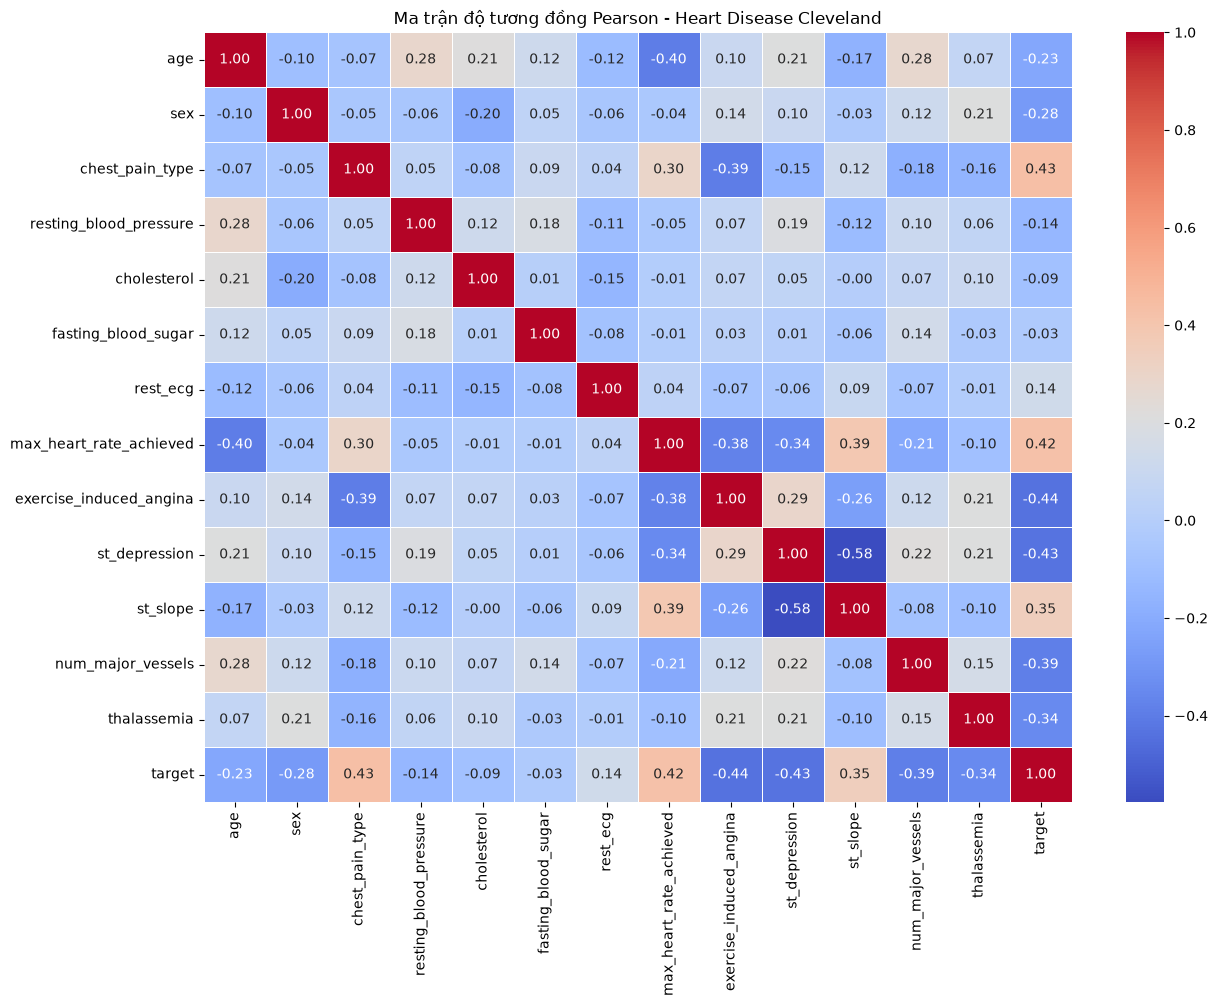

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079

Nhận xét tương quan:
1. Tương quan với biến mục tiêu 'target':
   - 'chest_pain_type' (loại đau ngực) có tương quan dương mạnh nhất với target (r = 0.43).
   - 'max_heart_rate_achieved' (nhịp tim tối đa) có tương quan dương (r = 0.42).
   - 'exercise_induced_angina' (đau ngực khi gắng sức) và 'st_depression' có tương quan âm vừa phải với target (r = -0.44 và r = -0.43).
2. Tương quan giữa các thuộc tính dự đoán độc lập:
   - Hệ số tương quan cao nhất giữa hai biến dự đoán là giữa 'st_slope' và 'st_depression' (r = -0.58).
   - Không có cặp biến dự đoán nào có tương quan vượt ngưỡng loại bỏ (|r| > 0.85). Do đó, giữ nguyên toàn bộ 13 thuộc tính.


In [3]:
# Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
plt.figure(figsize=(14, 10))
corr_heart = df_heart.corr(method='pearson')
sns.heatmap(corr_heart, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận độ tương đồng Pearson - Heart Disease Cleveland")
plt.show()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print()
print("Nhận xét tương quan:")
print("1. Tương quan với biến mục tiêu 'target':")
print("   - 'chest_pain_type' (loại đau ngực) có tương quan dương mạnh nhất với target (r = 0.43).")
print("   - 'max_heart_rate_achieved' (nhịp tim tối đa) có tương quan dương (r = 0.42).")
print("   - 'exercise_induced_angina' (đau ngực khi gắng sức) và 'st_depression' có tương quan âm vừa phải với target (r = -0.44 và r = -0.43).")
print("2. Tương quan giữa các thuộc tính dự đoán độc lập:")
print("   - Hệ số tương quan cao nhất giữa hai biến dự đoán là giữa 'st_slope' và 'st_depression' (r = -0.58).")
print("   - Không có cặp biến dự đoán nào có tương quan vượt ngưỡng loại bỏ (|r| > 0.85). Do đó, giữ nguyên toàn bộ 13 thuộc tính.")

### Câu 4: Tách các cột dữ liệu thành hai phần
- Phần 1 (X): Chứa 13 thuộc tính lâm sàng dự đoán (features).
- Phần 2 (y): Chứa thuộc tính quyết định 'target' (0: không bệnh, 1: có bệnh tim).

In [4]:
# Câu 4: Tách các cột dữ liệu thành hai phần
X = df_heart.drop(columns=['target'])
y = df_heart['target']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập thuộc tính dự đoán (X): {X.shape}")
print(f"Kích thước thuộc tính quyết định (y): {y.shape}")
print(f"Số lượng mẫu không mắc bệnh tim (0): {(y == 0).sum()}")
print(f"Số lượng mẫu có mắc bệnh tim (1): {(y == 1).sum()}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập thuộc tính dự đoán (X): (303, 13)
Kích thước thuộc tính quyết định (y): (303,)
Số lượng mẫu không mắc bệnh tim (0): 138
Số lượng mẫu có mắc bệnh tim (1): 165
